In [2]:
import os
import xarray as xr
from datetime import timedelta
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import scipy.stats as stats
import pandas as pd
import colormaps as cmaps
import cartopy.crs as ccrs
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
from scipy.stats import gaussian_kde
from eofs.xarray import Eof
import scipy.signal as sig
import cartopy.feature as cfeature

In [3]:
#custom colormap
import pickle

# Load the colormap
with open("fog_colormap.pkl", "rb") as f:
    fog_cmap = pickle.load(f)

In [4]:
cloud_study = xr.open_dataset("data/cesm_StdModel/cloud_std_study.nc")
cloud_study = cloud_study.CLOUD
cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 192, lon: 288)> Size: 133MB
[33177600 values with dtype=float32]
Coordinates:
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

In [5]:
#grid data 
#NOTE: the grid and mask (added later) do not perfectly align with EECRA but gets as close a possible.
lat_bins = np.arange(-90, 90, 5) + 2.5
lon_bins = np.arange(0, 360, 5) + 2.5

cloud_study_coarse = cloud_study.interp({"lat":lat_bins, "lon":lon_bins})
cloud_study_coarse

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[0.25396306, 0.25973236, 0.26440654, ..., 0.20734362,
         0.22451959, 0.23952464],
        [0.22594745, 0.20184294, 0.16730699, ..., 0.29313592,
         0.24517083, 0.22960254],
        [0.09387631, 0.08403551, 0.13689781, ..., 0.09253962,
         0.10548303, 0.09865723],
        ...,
        [0.42112739, 0.18216947, 0.40015861, ..., 0.4173181 ,
         0.56787151, 0.59199374],
        [0.59280647, 0.60597173, 0.58144019, ..., 0.55869891,
         0.51962261, 0.54718244],
        [0.6165308 , 0.61232276, 0.60835677, ..., 0.61271455,
         0.60730569, 0.61207062]],

       [[0.38069485, 0.39664117, 0.39487301, ..., 0.28840981,
         0.31954486, 0.3593642 ],
        [0.36516936, 0.38027725, 0.32878982, ..., 0.36433219,
         0.32949032, 0.3262036 ],
        [0.22760939, 0.21167366, 0.237215  , ..., 0.12286375,
         0.19461168, 0.21267668],
...
        [0.21748267, 0.0387754 , 0.2173701 , ..., 0.39789331,
         0.48891746, 0.48178504],
        [0.47684328, 0.52686212, 0.55110547, ..., 0.3789197 ,
         0.39667541, 0.42407045],
        [0.47522135, 0.47778362, 0.47872055, ..., 0.44100407,
         0.44465243, 0.45631869]],

       [[0.16320578, 0.16236933, 0.16528866, ..., 0.15948155,
         0.15806758, 0.16308061],
        [0.07508517, 0.06890044, 0.0745905 , ..., 0.04187294,
         0.02959593, 0.04761442],
        [0.04453059, 0.12123633, 0.18361833, ..., 0.0506851 ,
         0.04317118, 0.02492729],
        ...,
        [0.40523772, 0.16627519, 0.42354916, ..., 0.55151959,
         0.6981952 , 0.74373859],
        [0.72470427, 0.69187726, 0.68364609, ..., 0.61797405,
         0.73897767, 0.76272182],
        [0.72232427, 0.72810666, 0.73402736, ..., 0.72281305,
         0.71442853, 0.71812235]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

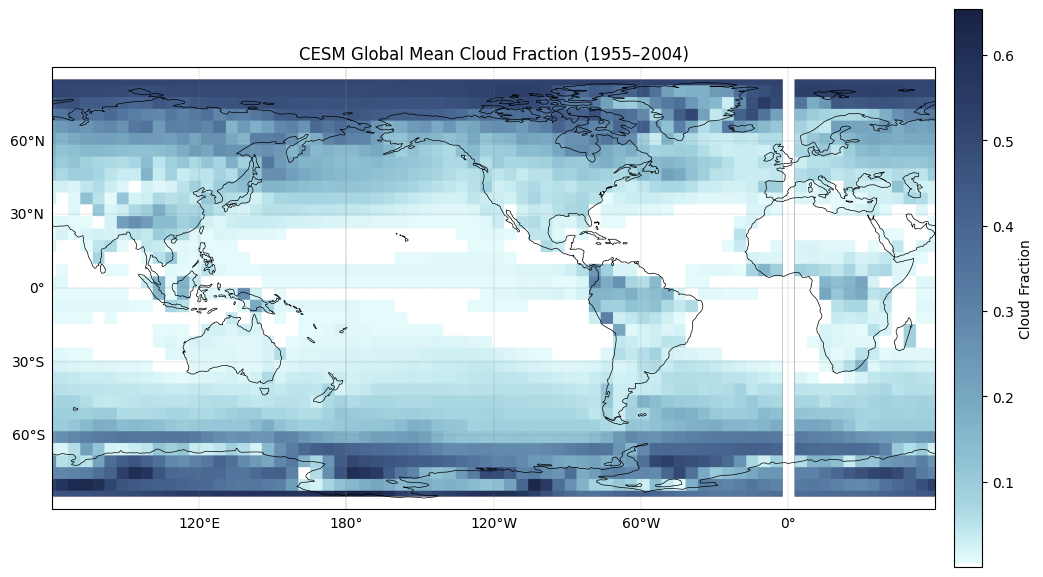

In [6]:
# Compute global mean gridded 
global_mean = cloud_study_coarse.mean("time")

# Coordinates
lat = global_mean['lat'].values
lon = global_mean['lon'].values

# Plot
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=240)}
)


im = ax.imshow(
    global_mean,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    cmap=fog_cmap,
    vmin=np.nanmin(global_mean),
    vmax=np.nanmax(global_mean),
    transform=ccrs.PlateCarree()
)

ax.set_title("CESM Global Mean Cloud Fraction (1955–2004)")
ax.coastlines(linewidth=0.5)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.7, linestyle="--")
gl.right_labels = False
gl.top_labels = False

# Colorbar
cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.03, pad=0.02)
cbar.set_label("Cloud Fraction")

plt.show()


In [7]:
# mask gridded data 
# NOTE: mask is (time:600 lat:36 lon:72), it is created from EECRA
# mask is created in 02visualizeEECRA.ipynb and saved to folder 

mask_df = pd.read_csv("data/EECRA/5yr_seasonal_study/mask.csv", sep=',', header=None )
mask = xr.DataArray(mask_df.values, dims=["lat", "lon"])

masked_cloud_study = cloud_study_coarse.where(mask)

masked_cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

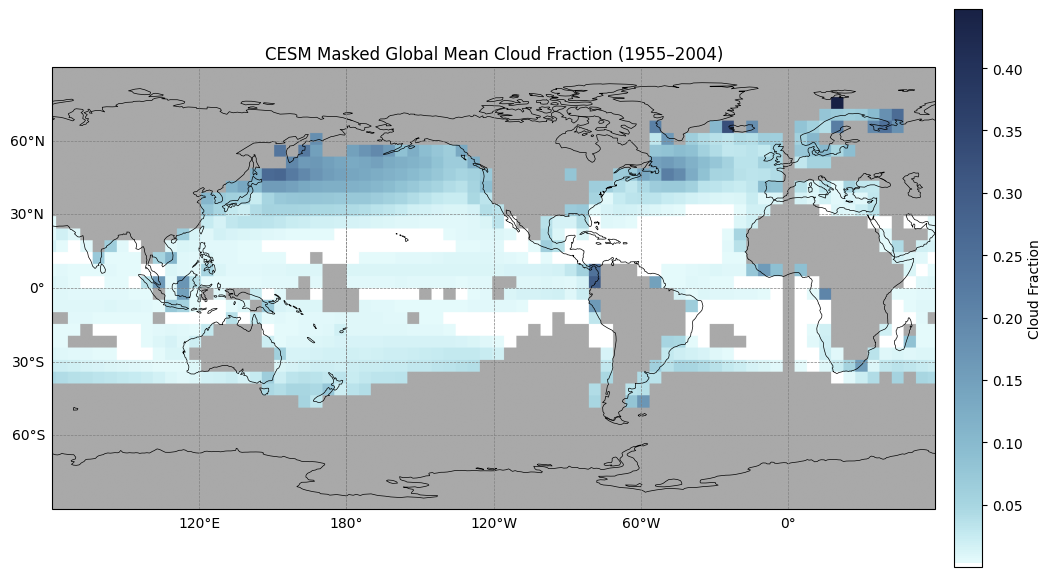

In [8]:
# Compute masked global mean
#import matplotlib.ticker as mticker
global_mean = masked_cloud_study.mean("time")

# Coordinates
lat = global_mean['lat'].values
lon = global_mean['lon'].values

# Plot
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=240)}
)

fog_cmap.set_bad('darkgray')
im = ax.imshow(
    global_mean,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    cmap=fog_cmap,
    vmin=np.nanmin(global_mean),
    vmax=np.nanmax(global_mean),
    transform=ccrs.PlateCarree()
)

ax.set_title("CESM Masked Global Mean Cloud Fraction (1955–2004)")
ax.coastlines(linewidth=0.5)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="gray", linestyle="--")
#gl.xlocator = mticker.FixedLocator([122.5, -122.5, -72.5, -2.5]) #for checking the lat/lon of 
#gl.ylocator = mticker.FixedLocator([32.5, 57.5, 37.5, 67.5])
gl.right_labels = False
gl.top_labels = False

# Colorbar
cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.03, pad=0.02)
cbar.set_label("Cloud Fraction")

plt.show()

Seasonal Climatology (to check data)

In [9]:
def select_season(data, months, season_name):
    # Filter by month
    season_data = data.where(data.month.isin(months), drop=True)
    
    # For DJF, we need to handle the year roll
    if season_name == 'DJF':
        # Drop December of the last year to avoid incomplete season
        last_month = season_data.time[-1].dt.month.item()
        if last_month == 12:
            # Drop the last time entry if it's December
            season_data = season_data.isel(time=slice(0, -1))
        
    return season_data

djf = select_season(masked_cloud_study, [12, 1, 2], "DJF").mean("time")
mam = select_season(masked_cloud_study, [3, 4, 5], "MAM").mean("time")
jja = select_season(masked_cloud_study, [6, 7, 8], "JJA").mean("time")
son = select_season(masked_cloud_study, [9, 10, 11], "SON").mean("time")

djf_data = djf.values
mam_data = mam.values
jja_data = jja.values
son_data = son.values

In [10]:
djf

<xarray.DataArray 'CLOUD' (lat: 36, lon: 72)> Size: 21kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(36, 72))
Coordinates:
    lev      float64 8B 992.6
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5

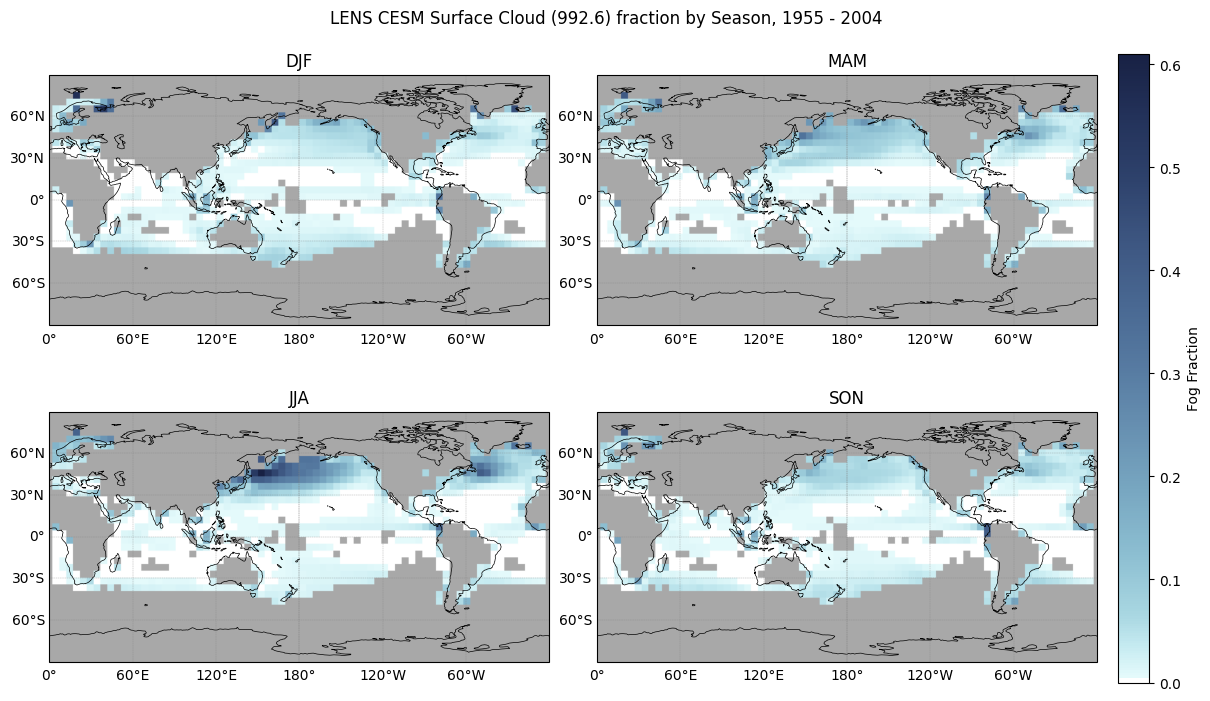

In [11]:
#seasonal
# Coordinates (for labeling)
lat = djf['lat'].values
lon = djf['lon'].values

fig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True, 
                        gridspec_kw={'hspace': 0, 'wspace': 0}, 
                        subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}, )
fig.suptitle("LENS CESM Surface Cloud (992.6) fraction by Season, 1955 - 2004")

# Set shared color range (optional)
vmin = np.nanmin([djf, mam, jja, son])
vmax = np.nanmax([djf, mam, jja, son])
fog_cmap.set_bad('darkgray')

datasets = [(djf_data, "DJF"), (mam_data, "MAM"), (jja_data, "JJA"), (son_data, "SON")]

for ax, (data, title) in zip(axs.flat, datasets):
    im = ax.imshow(
        data,
        origin="lower",
        extent=[lon.min(), lon.max(), lat.min(), lat.max()],
        cmap=fog_cmap,
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.7, linestyle="--")
    gl.right_labels = False
    gl.top_labels = False

# Add a colorbar
cbar = fig.colorbar(im, ax=axs, orientation='vertical', fraction=0.03, pad=0.02, label='Fog Fraction')

plt.savefig("dataViz/LENS_Global_Seasonal_Map")
plt.show()

NA and NP distributions - wip

In [12]:
#make masked study area cloud da

#left, right, bottom, top
#lon_min, lon_max, lat_min, lat_max

NP = [122.5, 237.5, 32.5, 57.5]
NA = [287.5, 357.5, 37.5, 67.5]


#make masked study area cloud da
cloud_study_NP = masked_cloud_study.sel(
    lon=slice(NP[0], NP[1]),
    lat=slice(NP[2], NP[3])
)
cloud_study_NP_xr = xr.DataArray(cloud_study_NP.values, dims=["time", "lat", "lon"])

#NOTE: no clue why but the cloud_study_NA is one cell taller and wider than the cloud_study_NA in EECRA
cloud_study_NA = masked_cloud_study.sel(
    lon=slice(NA[0], NA[1]),
    lat=slice(NA[2], NA[3])
)
cloud_study_NA_xr = xr.DataArray(cloud_study_NA.values, dims=["time", "lat", "lon"])

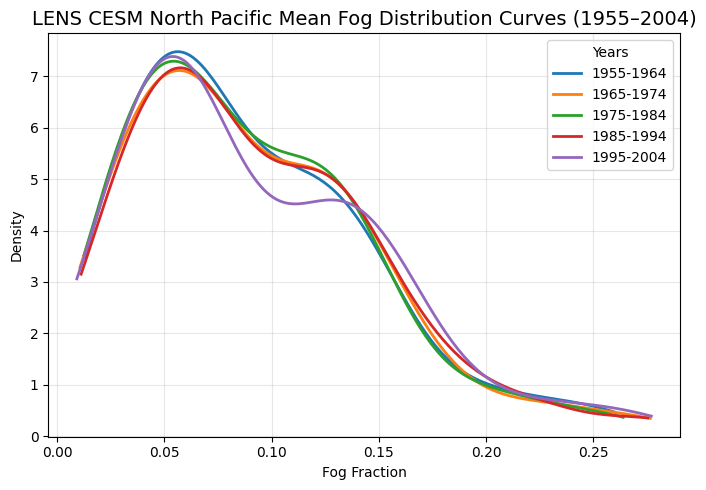

In [13]:
#NP curves on top of eachother

# Define year chunks (start, end) inclusive
year_ranges = [
    (1955, 1964),
    (1965, 1974),
    (1975, 1984),
    (1985, 1994),
    (1995, 2004)
]

plt.figure(figsize=(7, 5))

for i, (start, end) in enumerate(year_ranges):
    # Select the time slice (adjust selector to match your dataset's time handling)
    data_slice = cloud_study_NP.sel(time=slice(str(start)+"-01-01", str(end)+"-12-31"))
    
    # Mean over time
    data_mean = data_slice.mean(dim="time").values
    
    # Remove NaNs
    data_clean = data_mean[~np.isnan(data_mean)]
    
    # KDE for smooth curve
    kde = gaussian_kde(data_clean)
    x_vals = np.linspace(data_clean.min(), data_clean.max(), 200)
    y_vals = kde(x_vals)
    
    plt.plot(x_vals, y_vals, label=f"{start}-{end}", linewidth=2)

# Labels & legend
plt.title("LENS CESM North Pacific Mean Fog Distribution Curves (1955–2004)", fontsize=14)
plt.xlabel("Fog Fraction")
plt.ylabel("Density")
plt.legend(title="Years")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("dataViz/LENS_NP_KDEFogDistributionStacked")
plt.show()

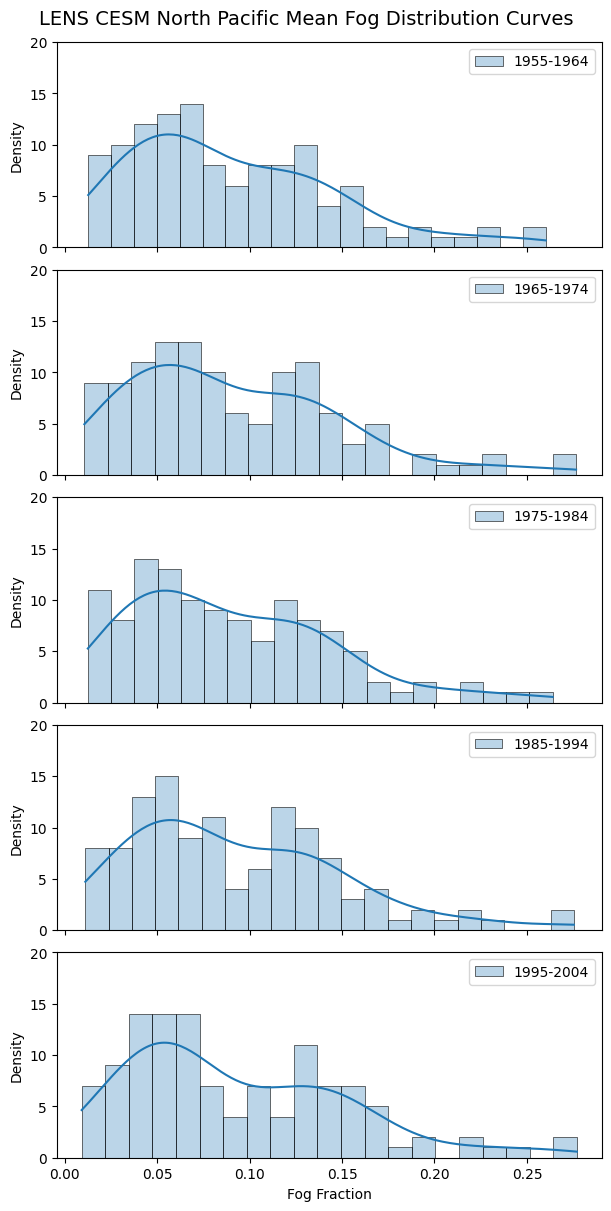

In [14]:
#NP bars and curves as seperate figures

year_ranges = [
    (1955, 1964),
    (1965, 1974),
    (1975, 1984),
    (1985, 1994),
    (1995, 2004)
]

fig, axs = plt.subplots(len(year_ranges), 1, figsize=(6, 12), sharex=True, layout="compressed")

kwargs = dict(hist_kws={'alpha':.6}, kde_kws={'linewidth':2})

for i, (start, end) in enumerate(year_ranges):
    # Select the time slice (adjust selector to match your dataset's time handling)
    data_slice = cloud_study_NP.sel(time=slice(str(start)+"-01-01", str(end)+"-12-31"))
    
    # Mean over time
    data_mean = data_slice.mean(dim="time").values
    
    # Remove NaNs
    data_clean = data_mean[~np.isnan(data_mean)]
    
    sns.histplot(data=pd.DataFrame(data_clean), kde=True, 
                 ax=axs[i], label=f"{start}-{end}", binwidth= 0.0125,
                 alpha=0.3, linewidth= 0.4)
    axs[i].set_ylim(0, 20)
    axs[i].set_ylabel("Density")
    axs[i].legend()

# Shared title and labels
fig.suptitle("LENS CESM North Pacific Mean Fog Distribution Curves", fontsize=14)
axs[-1].set_xlabel("Fog Fraction")

plt.savefig("dataViz/LENS_NP_KDEandBarFogDistribution")
plt.show()

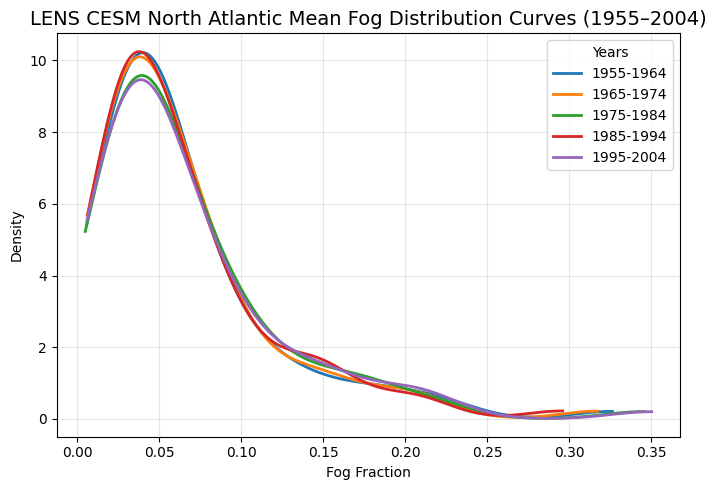

In [15]:
#NA curves on top of eachother

# Define year chunks (start, end) inclusive
year_ranges = [
    (1955, 1964),
    (1965, 1974),
    (1975, 1984),
    (1985, 1994),
    (1995, 2004)
]

plt.figure(figsize=(7, 5))

for i, (start, end) in enumerate(year_ranges):
    # Select the time slice (adjust selector to match your dataset's time handling)
    data_slice = cloud_study_NA.sel(time=slice(str(start)+"-01-01", str(end)+"-12-31"))
    
    # Mean over time
    data_mean = data_slice.mean(dim="time").values
    
    # Remove NaNs
    data_clean = data_mean[~np.isnan(data_mean)]
    
    # KDE for smooth curve
    kde = gaussian_kde(data_clean)
    x_vals = np.linspace(data_clean.min(), data_clean.max(), 200)
    y_vals = kde(x_vals)
    
    plt.plot(x_vals, y_vals, label=f"{start}-{end}", linewidth=2)

# Labels & legend
plt.title("LENS CESM North Atlantic Mean Fog Distribution Curves (1955–2004)", fontsize=14)
plt.xlabel("Fog Fraction")
plt.ylabel("Density")
plt.legend(title="Years")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("dataViz/LENS_NA_KDEFogDistributionStacked")
plt.show()

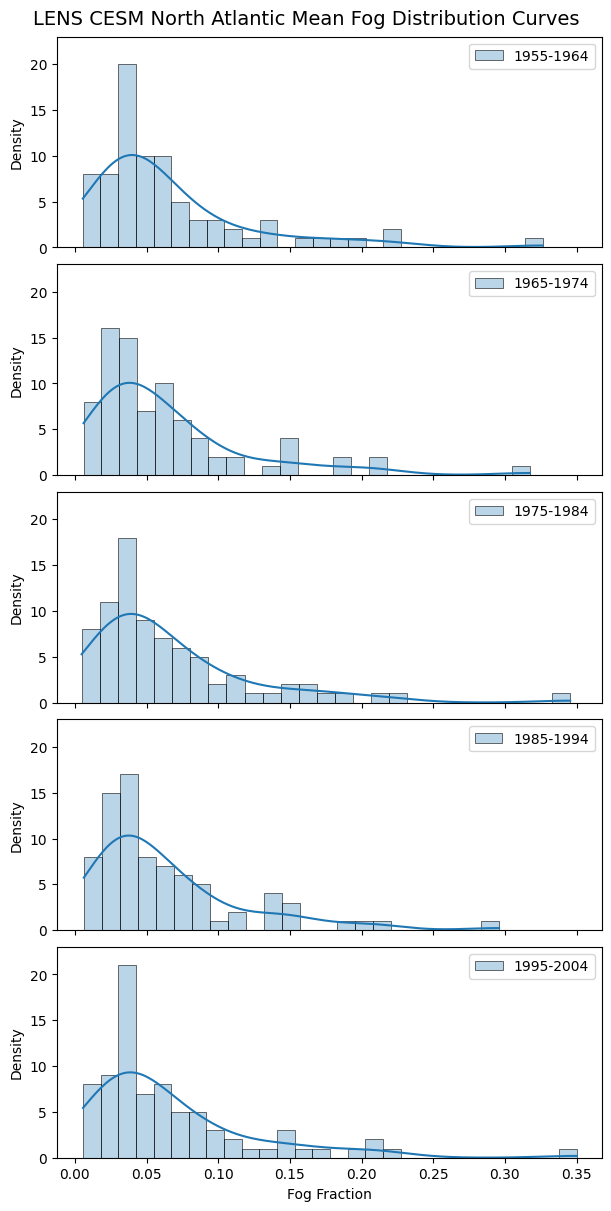

In [16]:
#NA bars and curves as seperate figures

year_ranges = [
    (1955, 1964),
    (1965, 1974),
    (1975, 1984),
    (1985, 1994),
    (1995, 2004)
]

fig, axs = plt.subplots(len(year_ranges), 1, figsize=(6, 12), sharex=True, layout="compressed")

kwargs = dict(hist_kws={'alpha':.6}, kde_kws={'linewidth':2})

for i, (start, end) in enumerate(year_ranges):
    # Select the time slice (adjust selector to match your dataset's time handling)
    data_slice = cloud_study_NA.sel(time=slice(str(start)+"-01-01", str(end)+"-12-31"))
    
    # Mean over time
    data_mean = data_slice.mean(dim="time").values
    
    # Remove NaNs
    data_clean = data_mean[~np.isnan(data_mean)]
    
    sns.histplot(data=pd.DataFrame(data_clean), kde=True, 
                 ax=axs[i], label=f"{start}-{end}", binwidth= 0.0125,
                 alpha=0.3, linewidth= 0.4)
    axs[i].set_ylim(0, 23)
    axs[i].set_ylabel("Density")
    axs[i].legend()

# Shared title and labels
fig.suptitle("LENS CESM North Atlantic Mean Fog Distribution Curves", fontsize=14)
axs[-1].set_xlabel("Fog Fraction")

plt.savefig("dataViz/LENS_NA_KDEandBarFogDistribution")
plt.show()

In [17]:
cloud_study_NA.lon

<xarray.DataArray 'lon' (lon: 15)> Size: 120B
array([287.5, 292.5, 297.5, 302.5, 307.5, 312.5, 317.5, 322.5, 327.5, 332.5,
       337.5, 342.5, 347.5, 352.5, 357.5])
Coordinates:
    lev      float64 8B ...
  * lon      (lon) float64 120B 287.5 292.5 297.5 302.5 ... 347.5 352.5 357.5
Attributes:
    long_name:  longitude
    units:      degrees_east

In [18]:
cloud_study_NA["lon"]

<xarray.DataArray 'lon' (lon: 15)> Size: 120B
array([287.5, 292.5, 297.5, 302.5, 307.5, 312.5, 317.5, 322.5, 327.5, 332.5,
       337.5, 342.5, 347.5, 352.5, 357.5])
Coordinates:
    lev      float64 8B ...
  * lon      (lon) float64 120B 287.5 292.5 297.5 302.5 ... 347.5 352.5 357.5
Attributes:
    long_name:  longitude
    units:      degrees_east

In [19]:
cloud_study_NA.lon[0].values

array(287.5)

In [20]:
[cloud_study_NA.lon[0].values, cloud_study_NA.lon[-1].values,
            cloud_study_NA.lat[0].values, cloud_study_NA.lat[-1].values],

([array(287.5), array(357.5), array(37.5), array(67.5)],)

In [21]:
# Define 5-year bins
bins = np.arange(1955, 2010, 5)   # [1955, 1960, ..., 2005, 2010]
labels = bins[:-1] 

# Assign each year to a 5-yr bin
cloud_5yr_NA = (
    cloud_study_NA
    .groupby_bins("year", bins=bins, labels=labels, right=False)  # right=False → includes 1955 in first bin
    .mean(dim="time")
)

# Rename new coordinate to something cleaner
cloud_5yr_NA = cloud_5yr_NA.rename({"year_bins": "time"})

In [22]:
# Define 5-year bins
bins = np.arange(1955, 2010, 5)   # [1955, 1960, ..., 2005, 2010]
labels = bins[:-1] 

# Assign each year to a 5-yr bin
cloud_5yr_NP = (
    cloud_study_NP
    .groupby_bins("year", bins=bins, labels=labels, right=False)  # right=False → includes 1955 in first bin
    .mean(dim="time")
)

# Rename new coordinate to something cleaner
cloud_5yr_NP = cloud_5yr_NP.rename({"year_bins": "time"})

NA EOF

In [28]:
# --- Step 1: anomalies (remove mean over time)
anoms = cloud_5yr_NP - cloud_5yr_NP.mean(dim='time')

# --- Step 2: detrend along time
anoms = anoms.fillna(0)
anoms_detrend = sig.detrend(anoms, axis=0)


print(anoms_detrend.shape)
print(cloud_5yr_NA.shape)

(10, 6, 24)
(10, 7, 15)


In [24]:
# --- Step 1: anomalies (remove mean over time)
anoms = cloud_5yr_NP - cloud_5yr_NP.mean(dim='time')

# --- Step 2: detrend along time
anoms = anoms.fillna(0)
anoms_detrend = sig.detrend(anoms, axis=0)

anoms_detrend_xr = xr.DataArray(
    anoms_detrend,
    dims=["time", "lat", "lon"],
    coords={"time": cloud_5yr_NA["time"], "lat": cloud_5yr_NA["lat"], "lon": cloud_5yr_NA["lon"]},
    name="cloud_anoms_detrend"
)

# --- Step 3: weights (area weighting by latitude)
coslat = np.cos(np.deg2rad(anoms_detrend_xr['lat'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(anoms_detrend_xr, weights=wgts)

# --- Step 4: extract EOFs + PCs
eof = solver.eofsAsCorrelation(neofs=3)  # shape (mode, lat, lon)
pc = solver.pcs(npcs=3, pcscaling=1)
vf = solver.varianceFraction(neigs=3)

CoordinateValidationError: conflicting sizes for dimension 'lat': length 6 on the data but length 7 on coordinate 'lat'

In [29]:
#plot EOF NA

fig = plt.figure(figsize=(16,10))
fig.suptitle("CESM North Atlantic EOF (every 5 years, 1955 - 2004)", fontsize = 20)

gs = fig.add_gridspec(3, 2, width_ratios=[1.5,1], height_ratios=[1,1, .1], hspace=0.4, wspace=0.1)

# ----------- EOF 2
# Reshape into lat/lon DataArray with proper coords
eof1_xr = xr.DataArray(
    eof[0].values,   # just the first EOF
    dims=["lat", "lon"],
    coords={"lat": cloud_5yr_NA["lat"].values, "lon": cloud_5yr_NA["lon"].values},
    name="EOF1"
)

# --- EOF1 Map ---
ax_map1 = fig.add_subplot(gs[0,0], projection=ccrs.PlateCarree())
im = ax_map1.imshow(
    eof1_xr.values,
    origin="lower",
    extent=[cloud_5yr_NA.lon[0].values - 360, cloud_5yr_NA.lon[-1].values -360,
            cloud_5yr_NA.lat[0].values, cloud_5yr_NA.lat[-1].values],
    cmap=plt.cm.RdBu_r,
    vmin=-1, vmax=1,
    transform=ccrs.PlateCarree()
)
ax_map1.add_feature(cfeature.LAND, facecolor="w", edgecolor="k")
ax_map1.coastlines(linewidth=0.5)

gl = ax_map1.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}
ax_map1.set_title("EOF1 (Correlation), " + str("{:.2f}".format(float(vf[0].values))) + "% Variance Explained", fontsize=14)

# --- PC1 Time Series ---
ax_pc1 = fig.add_subplot(gs[0,1])
ax_pc1.plot(cloud_5yr_NA['time'], pc[:, 0], color='b', linewidth=2)
ax_pc1.axhline(0, color='k', linewidth=0.8)

# Axes labels and grid
ax_pc1.set_xlabel("Year", fontsize=12)
ax_pc1.set_ylabel("Normalized Units", fontsize=12)
ax_pc1.set_title("PC1 Time Series", fontsize=14)
ax_pc1.grid(True, linestyle='--', alpha=0.5)

# ----------- EOF 2
eof2_xr = xr.DataArray(
    eof[1].values,   # second EOF
    dims=["lat", "lon"],
    coords={"lat": cloud_5yr_NA["lat"].values, "lon": cloud_5yr_NA["lon"].values},
    name="EOF2"
)

# --- EOF2 Map ---
ax_map2 = fig.add_subplot(gs[1,0], projection=ccrs.PlateCarree())
im = ax_map2.imshow(
    eof2_xr.values,
    origin="lower",
    extent=[cloud_5yr_NA.lon[0].values - 360, cloud_5yr_NA.lon[-1].values -360,
            cloud_5yr_NA.lat[0].values, cloud_5yr_NA.lat[-1].values],
    cmap=plt.cm.RdBu_r,
    vmin=-1, vmax=1,
    transform=ccrs.PlateCarree()
)
ax_map2.add_feature(cfeature.LAND, facecolor="w", edgecolor="k")
ax_map2.coastlines(linewidth=0.5)

gl = ax_map2.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}
ax_map2.set_title("EOF2 (Correlation), " + str("{:.2f}".format(float(vf[1].values))) + "% Variance Explained", fontsize=14)


ax_colormap = fig.add_subplot(gs[2,0])
cb = fig.colorbar(im, cax=ax_colormap, orientation= "horizontal")
cb.set_label("Correlation Coefficient", fontsize=12)

# --- PC2 Time Series ---
ax_pc2 = fig.add_subplot(gs[1,1])
ax_pc2.plot(cloud_5yr_NA['time'], pc[:, 1], color='b', linewidth=2)
ax_pc2.axhline(0, color='k', linewidth=0.8)

# Axes labels and grid
ax_pc2.set_xlabel("Year", fontsize=12)
ax_pc2.set_ylabel("Normalized Units", fontsize=12)
ax_pc2.set_title("PC2 Time Series", fontsize=14)
ax_pc2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.savefig("dataViz/CESM_NA_EOFS.png")
plt.show()


NameError: name 'eof' is not defined

<Figure size 1600x1000 with 0 Axes>

NP EOF

In [30]:
# --- Step 1: anomalies (remove mean over time)
anoms = cloud_5yr_NP - cloud_5yr_NP.mean(dim='time')

# --- Step 2: detrend along time
anoms = anoms.fillna(0)
anoms_detrend = sig.detrend(anoms, axis=0)

anoms_detrend_xr = xr.DataArray(
    anoms_detrend,
    dims=["time", "lat", "lon"],
    coords={"time": cloud_5yr_NP["time"], "lat": cloud_5yr_NP["lat"], "lon": cloud_5yr_NP["lon"]},
    name="cloud_anoms_detrend"
)

# --- Step 3: weights (area weighting by latitude)
coslat = np.cos(np.deg2rad(anoms_detrend_xr['lat'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(anoms_detrend_xr, weights=wgts)

# --- Step 4: extract EOFs + PCs
eof = solver.eofsAsCorrelation(neofs=3)  # shape (mode, lat, lon)
pc = solver.pcs(npcs=3, pcscaling=1)
vf = solver.varianceFraction(neigs=3)

/var/folders/4m/h1r7bv6s65ggpt8gzk616wyh0000gn/T/ipykernel_71604/811952830.py:95: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


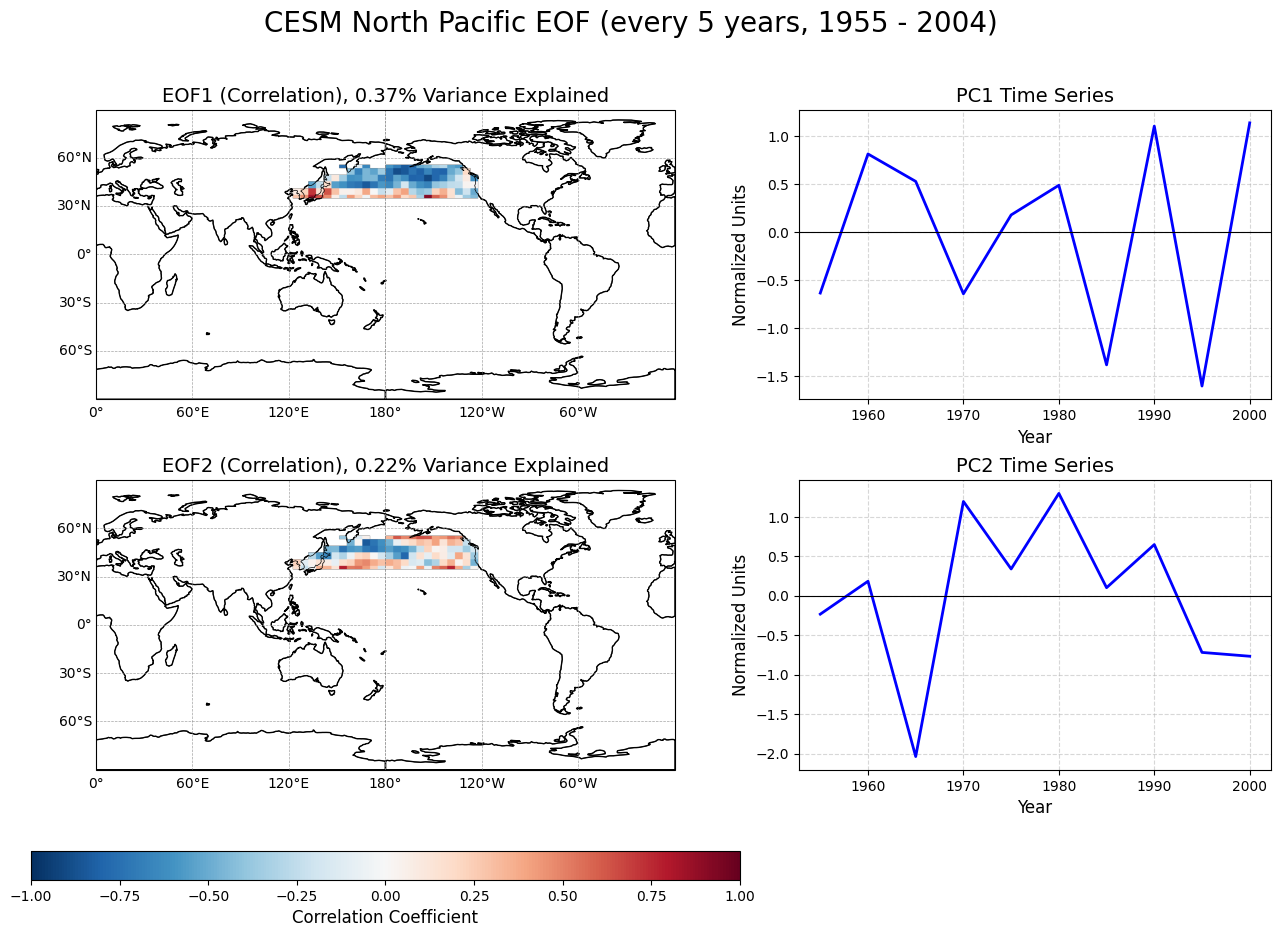

In [31]:
#plot EOF NP

fig = plt.figure(figsize=(16,10))
fig.suptitle("CESM North Pacific EOF (every 5 years, 1955 - 2004)", fontsize = 20)

gs = fig.add_gridspec(3, 2, width_ratios=[1.5,1], height_ratios=[1,1, .1], hspace=0.4, wspace=0.1)

# ----------- EOF 2
# Reshape into lat/lon DataArray with proper coords
eof1_xr = xr.DataArray(
    eof[0].values,   # just the first EOF
    dims=["lat", "lon"],
    coords={"lat": cloud_5yr_NP["lat"].values, "lon": cloud_5yr_NP["lon"].values},
    name="EOF1"
)

# --- EOF1 Map ---
ax_map1 = fig.add_subplot(gs[0,0], projection=ccrs.PlateCarree(central_longitude=180))
im = ax_map1.imshow(
    eof1_xr.values,
    origin="lower",
    extent=[cloud_5yr_NP.lon[0].values, cloud_5yr_NP.lon[-1].values,
            cloud_5yr_NP.lat[0].values, cloud_5yr_NP.lat[-1].values],
    cmap=plt.cm.RdBu_r,
    vmin=-1, vmax=1,
    transform=ccrs.PlateCarree()
)
ax_map1.add_feature(cfeature.LAND, facecolor="w", edgecolor="k")
ax_map1.coastlines(linewidth=0.5)

gl = ax_map1.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}
ax_map1.set_title("EOF1 (Correlation), " + str("{:.2f}".format(float(vf[0].values))) + "% Variance Explained", fontsize=14)

# --- PC1 Time Series ---
ax_pc1 = fig.add_subplot(gs[0,1])
ax_pc1.plot(cloud_5yr_NP['time'], pc[:, 0], color='b', linewidth=2)
ax_pc1.axhline(0, color='k', linewidth=0.8)

# Axes labels and grid
ax_pc1.set_xlabel("Year", fontsize=12)
ax_pc1.set_ylabel("Normalized Units", fontsize=12)
ax_pc1.set_title("PC1 Time Series", fontsize=14)
ax_pc1.grid(True, linestyle='--', alpha=0.5)

# ----------- EOF 2
eof2_xr = xr.DataArray(
    eof[1].values,   # second EOF
    dims=["lat", "lon"],
    coords={"lat": cloud_5yr_NP["lat"].values, "lon": cloud_5yr_NP["lon"].values},
    name="EOF2"
)

# --- EOF2 Map ---
ax_map2 = fig.add_subplot(gs[1,0], projection=ccrs.PlateCarree(central_longitude= 180))
im = ax_map2.imshow(
    eof2_xr.values,
    origin="lower",
    extent=[cloud_5yr_NP.lon[0].values, cloud_5yr_NP.lon[-1].values,
            cloud_5yr_NP.lat[0].values, cloud_5yr_NP.lat[-1].values],
    cmap=plt.cm.RdBu_r,
    vmin=-1, vmax=1,
    transform=ccrs.PlateCarree()
)
ax_map2.add_feature(cfeature.LAND, facecolor="w", edgecolor="k")
ax_map2.coastlines(linewidth=0.5)

gl = ax_map2.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}
ax_map2.set_title("EOF2 (Correlation), " + str("{:.2f}".format(float(vf[1].values))) + "% Variance Explained", fontsize=14)


ax_colormap = fig.add_subplot(gs[2,0])
cb = fig.colorbar(im, cax=ax_colormap, orientation= "horizontal")
cb.set_label("Correlation Coefficient", fontsize=12)

# --- PC2 Time Series ---
ax_pc2 = fig.add_subplot(gs[1,1])
ax_pc2.plot(cloud_5yr_NP['time'], pc[:, 1], color='b', linewidth=2)
ax_pc2.axhline(0, color='k', linewidth=0.8)

# Axes labels and grid
ax_pc2.set_xlabel("Year", fontsize=12)
ax_pc2.set_ylabel("Normalized Units", fontsize=12)
ax_pc2.set_title("PC2 Time Series", fontsize=14)
ax_pc2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.savefig("dataViz/CESM_NP_EOFS.png")
plt.show()
